# Working with imputed tracks

Experimental functional genomics atlases often have uneven assay coverage across
tissues and primary cell types. Single-cell assays (scRNA-seq and scATAC-seq)
cover many human primary cell types, whereas histone ChIP-seq (H3K27ac,
H3K27me3) is often missing outside well-profiled tissues such as blood.
AlphaGenome 2 predicts every track for every reference condition (`condition=`)
and labels each track with its `imputation_mode`. To condition predictions on
your own scRNA-seq count matrix instead, see
[Conditioning on your own single-cell data](https://www.alphagenomedocs.com/colabs/v2/conditioning_on_single_cell_data.html).

Here we inspect observed versus imputed chromatin tracks around *TCF7*
(encoding TCF-1, a master regulator of T-cell development and immune responses) across peripheral blood and bone marrow CD4+ T cells and B cells.

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)).

In [2]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import track_data
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import dna_client
from alphagenome.visualization import plot_components
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.transparent'] = False

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

## Load *TCF7* annotations

We load GENCODE v46 (hg38) MANE Select transcripts and define a 1 Mb
model input window (`sequence_interval`) and a 51.2 kb plotting window
(`plot_window`) centered on *TCF7*:

In [4]:
HG38_GTF_FEATHER = (
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf = pd.read_feather(HG38_GTF_FEATHER)
gtf_mane = gene_annotation.filter_to_mane_select_transcript(gtf)
transcript_extractor = transcript_utils.TranscriptExtractor(gtf_mane)

tcf7_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='TCF7')
sequence_interval = tcf7_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
plot_window = tcf7_interval.resize(51_200)
mane_transcripts = transcript_extractor.extract(plot_window)
pair_colors = ['#1f77b4', '#d95f02']

print(f'TCF7 gene interval: {tcf7_interval}')
print(f'1 Mb model input  : {sequence_interval}')
print(f'51.2 kb plot view : {plot_window}')

TCF7 gene interval: chr5:134114680-134151865:+
1 Mb model input  : chr5:133608985-134657561:+
51.2 kb plot view : chr5:134107673-134158873:+


## Check modality coverage across blood and bone marrow

Calling `dna_model.supported_conditions()` summarizes whether each output type is
`observed`, `imputed_supported`, or `imputed_exploratory` for every reference
condition (see
[Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html)
for how these modes are defined and pitfalls to avoid).

We compare peripheral blood (`UBERON:0000178`), where histone ChIP-seq was
experimentally measured, against bone marrow (`UBERON:0002371`), where only
single-cell assays (scATAC-seq and scRNA-seq) were measured and `CHIP_HISTONE` is
`imputed_supported`:

In [5]:
supported = dna_model.supported_conditions()

conditions = {
    'Blood Naive CD4+ T': 'UBERON:0000178_CL:0000895',
    'Blood CD4+ T': 'UBERON:0000178_CL:0000624',
    'Blood B': 'UBERON:0000178_CL:0000236',
    'Bone Marrow Naive CD4+ T': 'UBERON:0002371_CL:0000895',
    'Bone Marrow Naive B': 'UBERON:0002371_CL:0000788',
}
modality_cols = ['sc_atac', 'sc_gene_expression', 'chip_histone']
subset = supported[supported['condition'].isin(conditions.values())][
    ['condition', 'biosample_name'] + modality_cols
].sort_values('condition')

display(subset.reset_index(drop=True))

,condition,biosample_name,sc_atac,sc_gene_expression,chip_histone
0,UBERON:0000178_CL:0000236,blood B cell,observed,observed,observed
1,UBERON:0000178_CL:0000624,"blood CD4-positive, alpha-beta T cell",imputed_supported,imputed_supported,observed
2,UBERON:0000178_CL:0000895,"blood naive thymus-derived CD4-positive, alpha...",observed,observed,observed
3,UBERON:0002371_CL:0000788,bone marrow naive B cell,observed,observed,imputed_supported
4,UBERON:0002371_CL:0000895,"bone marrow naive thymus-derived CD4-positive,...",observed,observed,imputed_supported


## Predict tracks across conditions

We run `dna_model.predict_interval()` for `SC_ATAC` and `CHIP_HISTONE` across
the five reference conditions (we include both naive and total blood CD4+ T
cells because H3K27ac is observed in blood naive CD4+ T cells while
H3K27me3 is observed in total blood CD4+ T cells):

In [6]:
outputs = [
    dna_client.OutputType.SC_ATAC,
    dna_client.OutputType.CHIP_HISTONE,
]

preds = {
    name: dna_model.predict_interval(
        sequence_interval, requested_outputs=outputs, condition=cond
    )
    for name, cond in conditions.items()
}

See [Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html) for the rules governing within- and cross-modality imputation. Inspecting `metadata['imputation_mode']` shows that blood conditions mix observed and imputed histone tracks (within-modality imputation), whereas every bone marrow histone track is imputed from that condition's single-cell accessibility (cross-modality imputation):

In [7]:
summary_rows = []
for name, pred in preds.items():
  sc_meta = pred.sc_atac.metadata
  ch_meta = pred.chip_histone.metadata
  summary_rows.append({
      'Condition': name,
      'Biosample': sc_meta['biosample_name'].iloc[0],
      'sc_atac observed / total': (
          f"{(sc_meta['imputation_mode'] == 'observed').sum()}/{len(sc_meta)}"
      ),
      'chip_histone observed / total': (
          f"{(ch_meta['imputation_mode'] == 'observed').sum()}/{len(ch_meta)}"
      ),
  })

pd.DataFrame(summary_rows)

,Condition,Biosample,sc_atac observed / total,chip_histone observed / total
0,Blood Naive CD4+ T,"blood naive thymus-derived CD4-positive, alpha...",1/5,4/43
1,Blood CD4+ T,"blood CD4-positive, alpha-beta T cell",0/5,6/43
2,Blood B,blood B cell,1/5,11/43
3,Bone Marrow Naive CD4+ T,"bone marrow naive thymus-derived CD4-positive,...",1/5,0/43
4,Bone Marrow Naive B,bone marrow naive B cell,1/5,0/43


## Bone marrow 10x scATAC-seq

First, we extract the 10x nuclear scATAC-seq tracks in bone marrow
naive CD4+ T cells and naive B cells:

In [8]:
bm_sc_atac = track_data.concat([
    preds['Bone Marrow Naive CD4+ T'].sc_atac,
    preds['Bone Marrow Naive B'].sc_atac,
])
bm_sc_atac = bm_sc_atac.filter_tracks(
    bm_sc_atac.metadata['name'].str.contains('10X-cellranger').to_numpy()
)

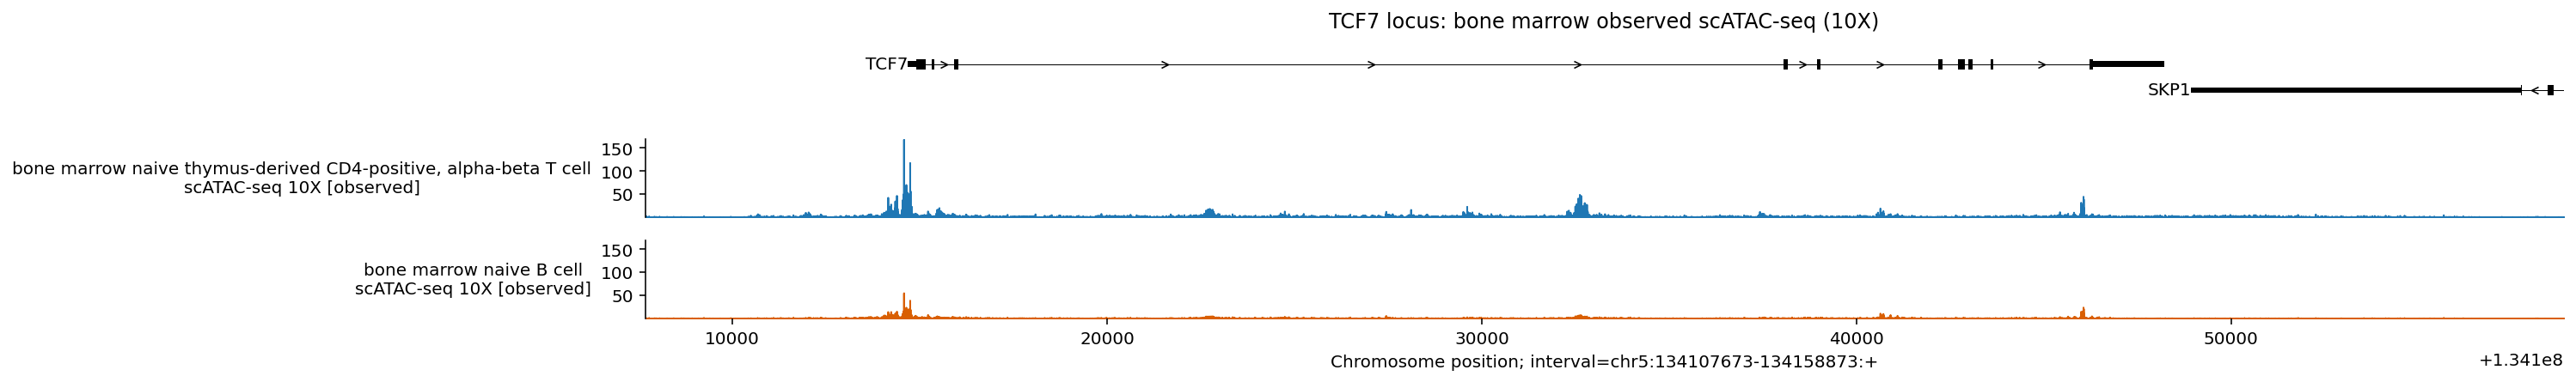

In [9]:
_ = plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(mane_transcripts),
        plot_components.Tracks(
            bm_sc_atac,
            ylabel_template=(
                '{biosample_name}\n{Assay title} [{imputation_mode}]'
            ),
            shared_y_scale=True,
            filled=True,
            track_colors=pair_colors,
        ),
    ],
    interval=plot_window,
    title='TCF7 locus: bone marrow observed scATAC-seq (10X)',
)
plt.show()

## Active mark (H3K27ac): observed blood vs imputed bone marrow

We keep single-end H3K27ac tracks, the channel observed in blood, and plot
observed blood (top) above imputed bone marrow (bottom):

In [10]:
blood_k27ac = track_data.concat([
    preds['Blood Naive CD4+ T'].chip_histone,
    preds['Blood B'].chip_histone,
])
blood_k27ac = blood_k27ac.filter_tracks(
    (
        (blood_k27ac.metadata['histone_mark'] == 'H3K27ac')
        & (blood_k27ac.metadata['endedness'] == 'single')
    ).to_numpy()
)

bm_k27ac = track_data.concat([
    preds['Bone Marrow Naive CD4+ T'].chip_histone,
    preds['Bone Marrow Naive B'].chip_histone,
])
bm_k27ac = bm_k27ac.filter_tracks(
    (
        (bm_k27ac.metadata['histone_mark'] == 'H3K27ac')
        & (bm_k27ac.metadata['endedness'] == 'single')
    ).to_numpy()
)

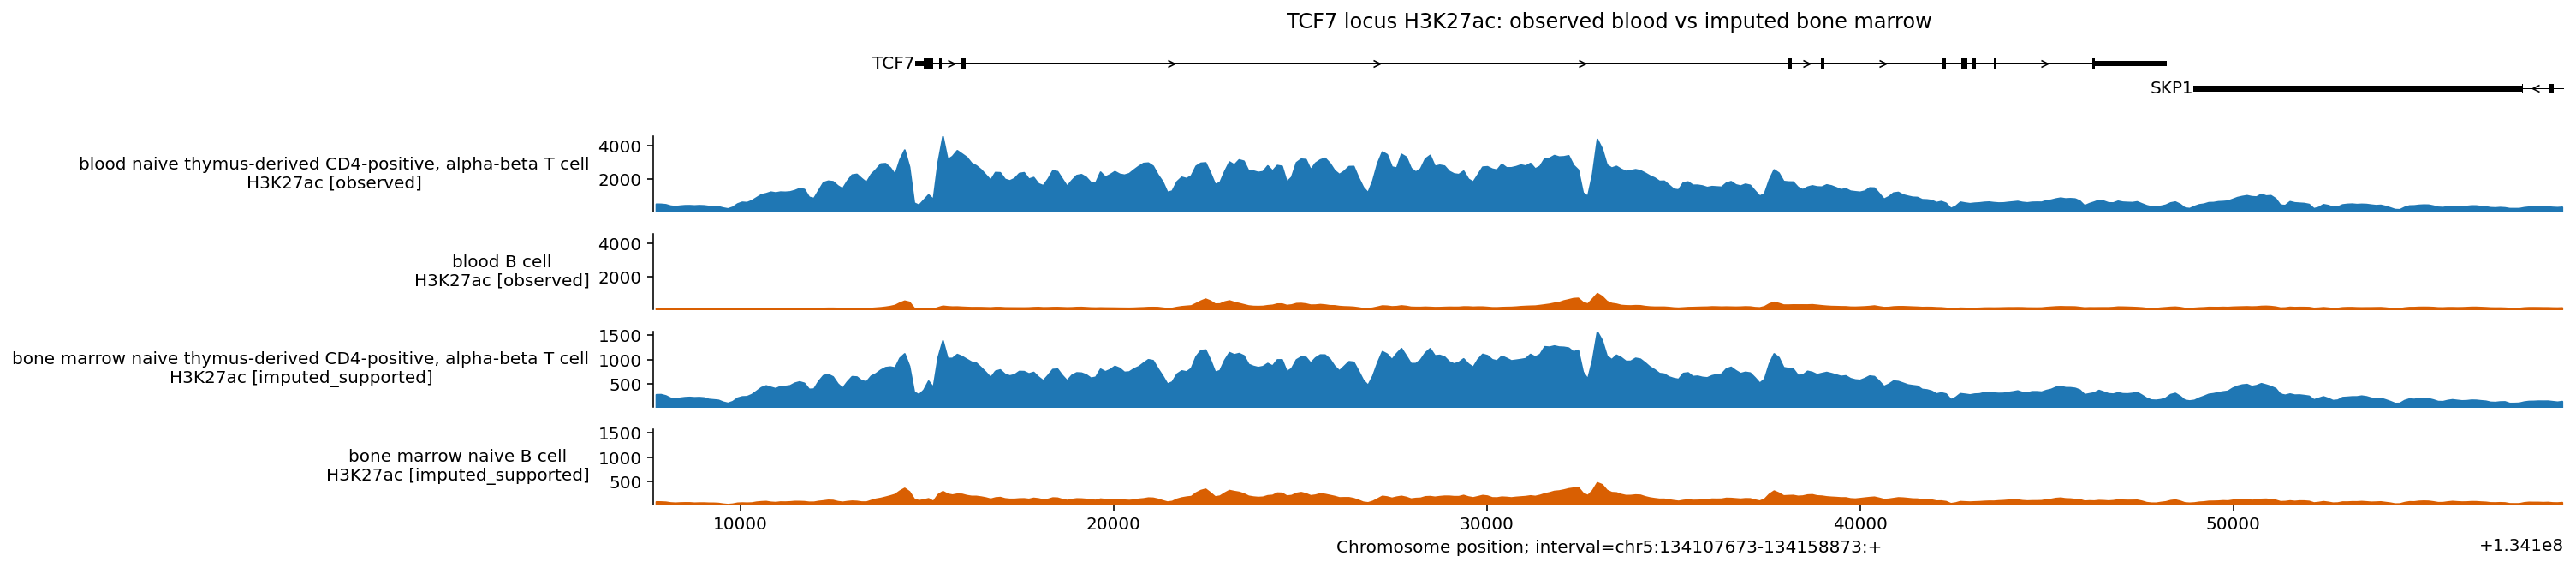

In [11]:
_ = plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(mane_transcripts),
        plot_components.Tracks(
            blood_k27ac,
            ylabel_template=(
                '{biosample_name}\n{histone_mark} [{imputation_mode}]'
            ),
            shared_y_scale=True,
            filled=True,
            track_colors=pair_colors,
        ),
        plot_components.Tracks(
            bm_k27ac,
            ylabel_template=(
                '{biosample_name}\n{histone_mark} [{imputation_mode}]'
            ),
            shared_y_scale=True,
            filled=True,
            track_colors=pair_colors,
        ),
    ],
    interval=plot_window,
    title='TCF7 locus H3K27ac: observed blood vs imputed bone marrow',
)
plt.show()

Imputed bone marrow H3K27ac in naive CD4+ T cells (bottom, blue) resembles the
broad acetylation domain spanning *TCF7* seen in observed blood CD4+ T cells
(top, blue), while B cells (orange) remain nearer to baseline in both tissues.

## Repressive mark (H3K27me3): observed blood vs imputed bone marrow

We repeat the comparison for H3K27me3, which is observed in total blood CD4+ T
cells and B cells:

In [12]:
blood_k27me3 = track_data.concat([
    preds['Blood CD4+ T'].chip_histone,
    preds['Blood B'].chip_histone,
])
blood_k27me3 = blood_k27me3.filter_tracks(
    (
        (blood_k27me3.metadata['histone_mark'] == 'H3K27me3')
        & (blood_k27me3.metadata['endedness'] == 'single')
    ).to_numpy()
)

bm_k27me3 = track_data.concat([
    preds['Bone Marrow Naive CD4+ T'].chip_histone,
    preds['Bone Marrow Naive B'].chip_histone,
])
bm_k27me3 = bm_k27me3.filter_tracks(
    (
        (bm_k27me3.metadata['histone_mark'] == 'H3K27me3')
        & (bm_k27me3.metadata['endedness'] == 'single')
    ).to_numpy()
)

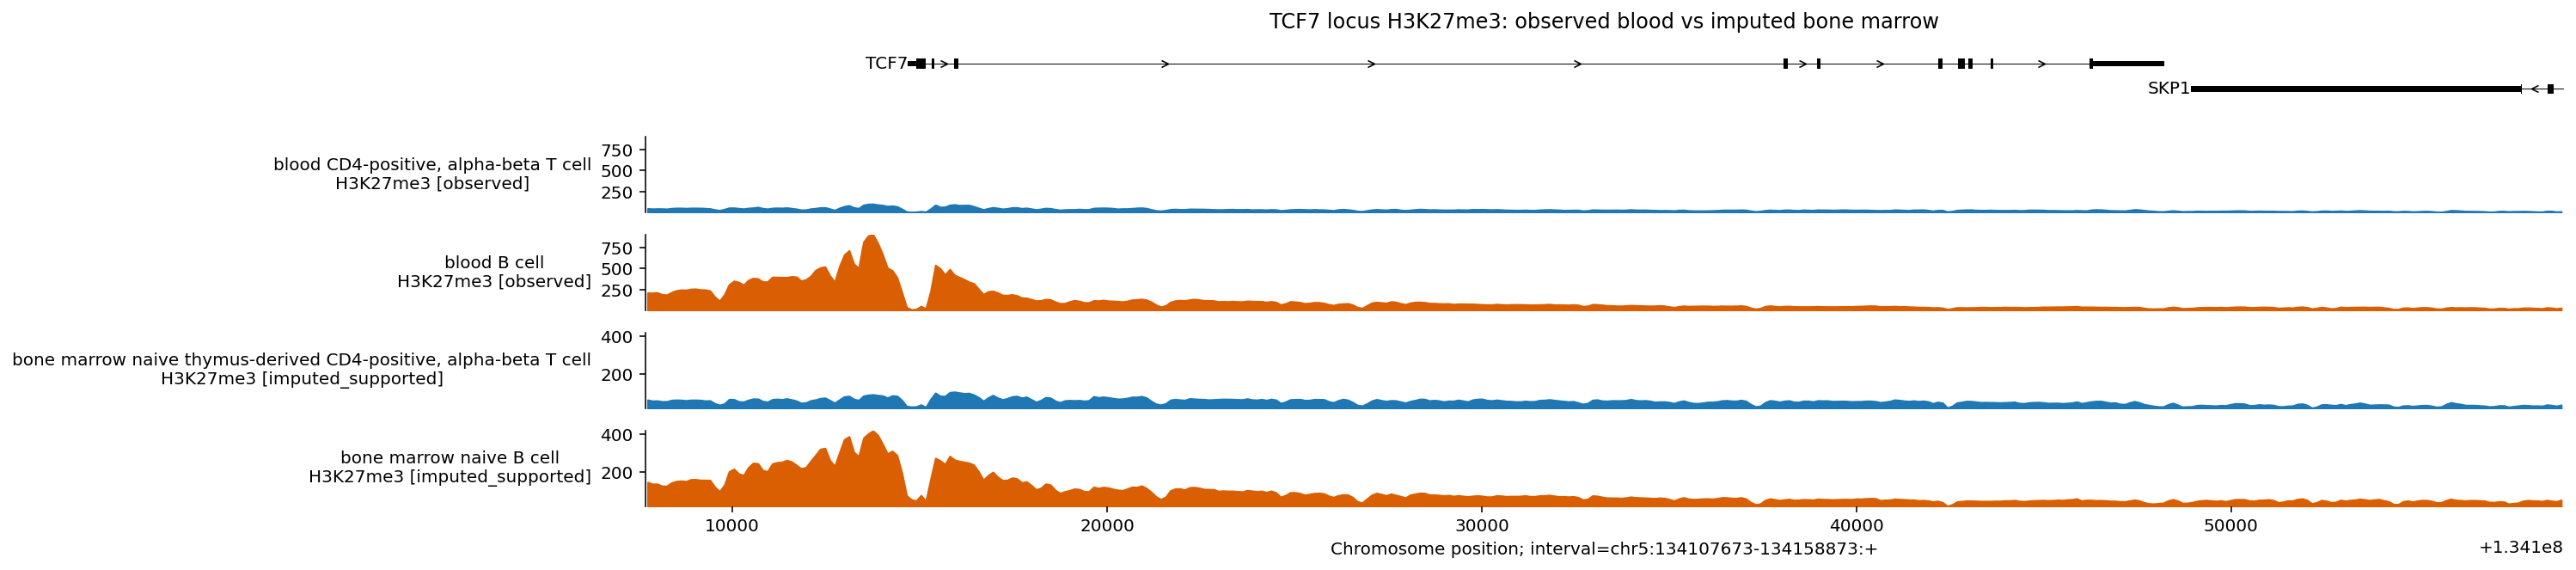

In [13]:
_ = plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(mane_transcripts),
        plot_components.Tracks(
            blood_k27me3,
            ylabel_template=(
                '{biosample_name}\n{histone_mark} [{imputation_mode}]'
            ),
            shared_y_scale=True,
            filled=True,
            track_colors=pair_colors,
        ),
        plot_components.Tracks(
            bm_k27me3,
            ylabel_template=(
                '{biosample_name}\n{histone_mark} [{imputation_mode}]'
            ),
            shared_y_scale=True,
            filled=True,
            track_colors=pair_colors,
        ),
    ],
    interval=plot_window,
    title='TCF7 locus H3K27me3: observed blood vs imputed bone marrow',
)
plt.show()

Imputed bone marrow H3K27me3 in naive B cells (bottom, orange) resembles the
focal Polycomb-repressive peak over the *TCF7* promoter seen in observed blood
B cells (top, orange), while CD4+ T cells (blue) remain closer to zero. Histone marks
imputed from chromatin accessibility follow a supported direction; see
[Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html) for more information.

## Next steps

- See [Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html) for imputation modes and reliability caveats.
- See [Conditioning on your own single-cell data](https://www.alphagenomedocs.com/colabs/v2/conditioning_on_single_cell_data.html) to condition predictions on your own scRNA-seq counts.